# Car Price Prediction Using Machine Learning

## Project Overview

This project uses machine learning to predict the price of a car based on its features such as make, model, year, engine specifications, transmission, vehicle type, and fuel economy.

A Random Forest Regression model is used for prediction and evaluated using MAE, RMSE, and R² score.

## Dataset

The dataset contains information about 11,914 cars and 16 attributes, including car specifications and MSRP (Manufacturer's Suggested Retail Price).

The dataset was obtained from Kaggle.

## Model Performance

The Random Forest Regression model was evaluated on the test dataset using three metrics:

- Mean Absolute Error (MAE): $3,608.58
- Root Mean Squared Error (RMSE): $21,736.10
- R² Score: 0.9025

The model achieved an R² score of 0.9025, indicating that it captured a substantial portion of the variation in car prices in the test data.

## Example Prediction

For an example BMW with specified engine, transmission, body, and fuel-economy features, the trained model predicted an MSRP of approximately $40,123.

The model can be used to estimate car prices from similar vehicle specifications.

In [79]:
import zipfile

with zipfile.ZipFile('/content/archive(2).zip', 'r') as zip_ref:
    zip_ref.extractall('/content/car_data_new')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [80]:
import os

for root, dirs, files in os.walk('/content/car_data_new'):
    for file in files:
        print(os.path.join(root, file))

/content/car_data_new/data.csv


In [81]:
import pandas as pd

file_path = '/content/car_data_new/data.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (11914, 16)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [82]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP', 'Engine Cylinders', 'Transmission Type', 'Driven_Wheels', 'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style', 'highway MPG', 'city mpg', 'Popularity', 'MSRP']

Data types:
Make                  object
Model                 object
Year                   int64
Engine Fuel Type      object
Engine HP            float64
Engine Cylinders     float64
Transmission Type     object
Driven_Wheels         object
Number of Doors      float64
Market Category       object
Vehicle Size          object
Vehicle Style         object
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

Missing values:
Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market 

In [83]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with the median
df["Engine HP"] = df["Engine HP"].fillna(df["Engine HP"].median())
df["Engine Cylinders"] = df["Engine Cylinders"].fillna(df["Engine Cylinders"].median())
df["Number of Doors"] = df["Number of Doors"].fillna(df["Number of Doors"].median())

# Fill missing categorical values
df["Engine Fuel Type"] = df["Engine Fuel Type"].fillna(df["Engine Fuel Type"].mode()[0])
df["Market Category"] = df["Market Category"].fillna("Unknown")

print("Cleaning completed!")
print("Rows and columns:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum().sum())

Cleaning completed!
Rows and columns: (11199, 16)

Remaining missing values:
0


In [84]:
X = df.drop(columns=["MSRP"])
y = df["MSRP"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("MSRP (Car Price)")

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:
['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP', 'Engine Cylinders', 'Transmission Type', 'Driven_Wheels', 'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style', 'highway MPG', 'city mpg', 'Popularity']

Target:
MSRP (Car Price)

Feature shape: (11199, 15)
Target shape: (11199,)


In [85]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8959
Testing samples: 2240


In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Make', 'Model', 'Engine Fuel Type', 'Transmission Type', 'Driven_Wheels', 'Market Category', 'Vehicle Size', 'Vehicle Style']

Numerical features:
['Year', 'Engine HP', 'Engine Cylinders', 'Number of Doors', 'highway MPG', 'city mpg', 'Popularity']


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [88]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [89]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-----------------")
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation
-----------------
MAE: $3,608.58
RMSE: $21,736.10
R² Score: 0.9025


In [90]:
sample_car = pd.DataFrame({
    "Make": ["BMW"],
    "Model": ["1 Series"],
    "Year": [2015],
    "Engine Fuel Type": ["premium unleaded (required)"],
    "Engine HP": [240],
    "Engine Cylinders": [4],
    "Transmission Type": ["MANUAL"],
    "Driven_Wheels": ["rear wheel drive"],
    "Number of Doors": [2],
    "Market Category": ["Luxury,Performance"],
    "Vehicle Size": ["Compact"],
    "Vehicle Style": ["Coupe"],
    "highway MPG": [30],
    "city mpg": [22],
    "Popularity": [3916]
})

predicted_price = model.predict(sample_car)[0]

print(f"Predicted Car Price: ${predicted_price:,.2f}")

Predicted Car Price: $40,123.07


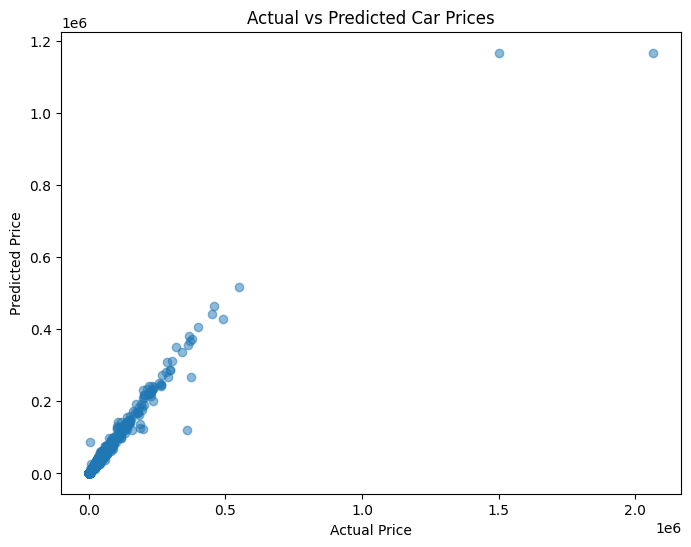

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()